In [8]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch Version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Enable T4 GPU from Runtime settings.")

PyTorch Version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


Load the Day 9 dataset partitions

In [19]:
DAY9_EXPORT = "/content/drive/MyDrive/Day9_Exports"

train_df = pd.read_csv(
    os.path.join(DAY9_EXPORT, "train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(DAY9_EXPORT, "val_split.csv")
)

test_df = pd.read_csv(
    os.path.join(DAY9_EXPORT, "test_split.csv")
)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print("\nTraining Labels:")
print(train_df["label"].value_counts())

print("\nValidation Labels:")
print(val_df["label"].value_counts())

print("\nTesting Labels:")
print(test_df["label"].value_counts())

# Verify that the exported image paths still exist
for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing = sum(
        not os.path.exists(p)
        for p in split_df["path"]
    )

    print(f"{split_name} missing images:", missing)

    if missing:
        raise FileNotFoundError(
            f"{split_name} contains missing image paths."
        )

Training Images: 10916
Validation Images: 2339
Testing Images: 2340

Training Labels:
label
1    7962
0    2954
Name: count, dtype: int64

Validation Labels:
label
1    1706
0     633
Name: count, dtype: int64

Testing Labels:
label
1    1707
0     633
Name: count, dtype: int64
Training missing images: 0
Validation missing images: 0
Testing missing images: 0


In [20]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/10.IIT_FELLOWSHIP/datasets/dataset_ginger_v1.zip"
target_dir = "/content/Master_Ginger_Dataset"

print(f"Extracting {zip_path} to {target_dir}...")
if os.path.exists(zip_path):
    os.makedirs(target_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(target_dir)
    print("Extraction complete!")
    print("Contents of extraction directory:", os.listdir(target_dir)[:10])
else:
    print(f"Error: Zip file not found at {zip_path}")

Extracting /content/drive/MyDrive/10.IIT_FELLOWSHIP/datasets/dataset_ginger_v1.zip to /content/Master_Ginger_Dataset...
Extraction complete!
Contents of extraction directory: ['Leaf_Blight', 'dataset_audit.txt', 'Master_Ginger_Dataset', 'Damage_Pest', 'Healthy', 'Bacterial_Wilt', 'Dehydrated']


In [21]:
import os
import shutil

# Fix nested folder structure if present
nested_dir = "/content/Master_Ginger_Dataset/Master_Ginger_Dataset"
target_dir = "/content/Master_Ginger_Dataset"

if os.path.exists(nested_dir):
    print("Detected nested Master_Ginger_Dataset folder. Moving contents up...")
    for item in os.listdir(nested_dir):
        shutil.move(os.path.join(nested_dir, item), os.path.join(target_dir, item))
    os.rmdir(nested_dir)
    print("Contents successfully moved!")

# Let's re-verify the missing images check
for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing = sum(not os.path.exists(p) for p in split_df["path"])
    print(f"{split_name} missing images:", missing)

Detected nested Master_Ginger_Dataset folder. Moving contents up...
Contents successfully moved!
Training missing images: 0
Validation missing images: 0
Testing missing images: 0


Configure Image processing

In [22]:
IMAGE_SIZE = 128
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("Day 9 preprocessing restored!")
print("Image Size:", IMAGE_SIZE)

Day 9 preprocessing restored!
Image Size: 128


In [23]:
class LeafDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        label = torch.tensor(
            row["label"],
            dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = LeafDataset(
    train_df, train_transform
)

val_dataset = LeafDataset(
    val_df, test_transform
)

test_dataset = LeafDataset(
    test_df, test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("All DataLoaders initialized!")

All DataLoaders initialized!


Implement the identity Residual Block

In [24]:
class ResidualBlock(nn.Module):

    def __init__(self, channels):

        super(ResidualBlock, self).__init__()

        self.f = nn.Sequential(

            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(channels)
        )

    def forward(self, x):

        identity = x

        output = self.f(x)

        output = output + identity

        return torch.relu(output)

Verify identity shortcut and tensor dimensions

In [25]:
block = ResidualBlock(32).to(device)

dummy_input = torch.randn(
    4, 32, 32, 32
).to(device)

dummy_output = block(dummy_input)

print("Input Shape:", dummy_input.shape)
print("Output Shape:", dummy_output.shape)

assert dummy_input.shape == dummy_output.shape

print("Identity shortcut verified successfully!")

Input Shape: torch.Size([4, 32, 32, 32])
Output Shape: torch.Size([4, 32, 32, 32])
Identity shortcut verified successfully!


Implement 1 × 1 projection shortcut

In [26]:
class ProjectionResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1
    ):

        super(ProjectionResidualBlock, self).__init__()

        self.f = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                stride=stride,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels)
        )

        self.shortcut = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                stride=stride,
                bias=False
            ),
            nn.BatchNorm2d(out_channels)
        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):

        identity = self.shortcut(x)

        output = self.f(x)

        output = output + identity

        return self.relu(output)


projection_block = ProjectionResidualBlock(
    16, 32, stride=2
).to(device)

sample = torch.randn(
    4, 16, 64, 64
).to(device)

result = projection_block(sample)

print("Input Shape:", sample.shape)
print("Output Shape:", result.shape)

assert result.shape == (4, 32, 32, 32)

print("Projection shortcut verified!")

Input Shape: torch.Size([4, 16, 64, 64])
Output Shape: torch.Size([4, 32, 32, 32])
Projection shortcut verified!


Build the Day 10 ResNet classifier

In [27]:
class ResNetLeafCNN(nn.Module):

    def __init__(self):

        super(ResNetLeafCNN, self).__init__()

        self.conv1 = nn.Sequential(

            nn.Conv2d(
                3, 16,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.conv2 = nn.Sequential(

            nn.Conv2d(
                16, 32,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.residual1 = ResidualBlock(32)
        self.residual2 = ResidualBlock(32)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.flatten = nn.Flatten()

        self.fc = nn.Linear(32, 1)

    def forward(self, x):

        x = self.conv1(x)

        x = self.conv2(x)

        x = self.residual1(x)

        x = self.residual2(x)

        x = self.global_pool(x)

        x = self.flatten(x)

        x = self.fc(x)

        return x


model = ResNetLeafCNN().to(device)

print(model)

print(
    "\nTotal Parameters:",
    sum(p.numel() for p in model.parameters())
)

ResNetLeafCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (residual1): ResidualBlock(
    (f): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), p

Configure loss function and optimizer

In [28]:
negative_count = (train_df["label"] == 0).sum()
positive_count = (train_df["label"] == 1).sum()

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32
).to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Positive Class Weight:", pos_weight.item())
print("Loss Function: BCEWithLogitsLoss")
print("Optimizer: Adam")

Positive Class Weight: 0.37101230025291443
Loss Function: BCEWithLogitsLoss
Optimizer: Adam


We train the residual network using forward propagation, loss calculation, backpropagation and Adam optimization. Training and validation losses and accuracies are recorded after each epoch. The checkpoint with the lowest validation loss is retained for final evaluation.

In [29]:
EPOCHS = 8

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")

DAY10_DIR = "/content/drive/MyDrive/Day10_ResNet"
os.makedirs(DAY10_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    DAY10_DIR,
    "best_resnet_leaf_model.pth"
)

for epoch in range(EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = (outputs >= 0).float()

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    # -------------------------
    # VALIDATION
    # -------------------------

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += (
                loss.item() * images.size(0)
            )

            predictions = (outputs >= 0).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    # Save best validation checkpoint
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Train Acc: {epoch_train_acc*100:.2f}% "
        f"Val Loss: {epoch_val_loss:.4f} "
        f"Val Acc: {epoch_val_acc*100:.2f}%"
    )

print("\nTraining Completed!")
print("Best Validation Loss:", best_val_loss)
print("Best Model:", BEST_MODEL_PATH)

Epoch [1/8] Train Loss: 0.2887 Train Acc: 71.08% Val Loss: 0.2693 Val Acc: 68.32%
Epoch [2/8] Train Loss: 0.2304 Train Acc: 78.80% Val Loss: 0.2128 Val Acc: 76.74%
Epoch [3/8] Train Loss: 0.2051 Train Acc: 81.60% Val Loss: 0.1861 Val Acc: 87.00%
Epoch [4/8] Train Loss: 0.1910 Train Acc: 82.45% Val Loss: 0.1781 Val Acc: 85.42%
Epoch [5/8] Train Loss: 0.1810 Train Acc: 83.76% Val Loss: 0.1729 Val Acc: 83.33%
Epoch [6/8] Train Loss: 0.1695 Train Acc: 84.82% Val Loss: 0.1557 Val Acc: 88.50%
Epoch [7/8] Train Loss: 0.1713 Train Acc: 84.45% Val Loss: 0.1523 Val Acc: 89.01%
Epoch [8/8] Train Loss: 0.1565 Train Acc: 85.75% Val Loss: 0.1520 Val Acc: 85.72%

Training Completed!
Best Validation Loss: 0.15196651921740145
Best Model: /content/drive/MyDrive/Day10_ResNet/best_resnet_leaf_model.pth


Plot training and validation curves

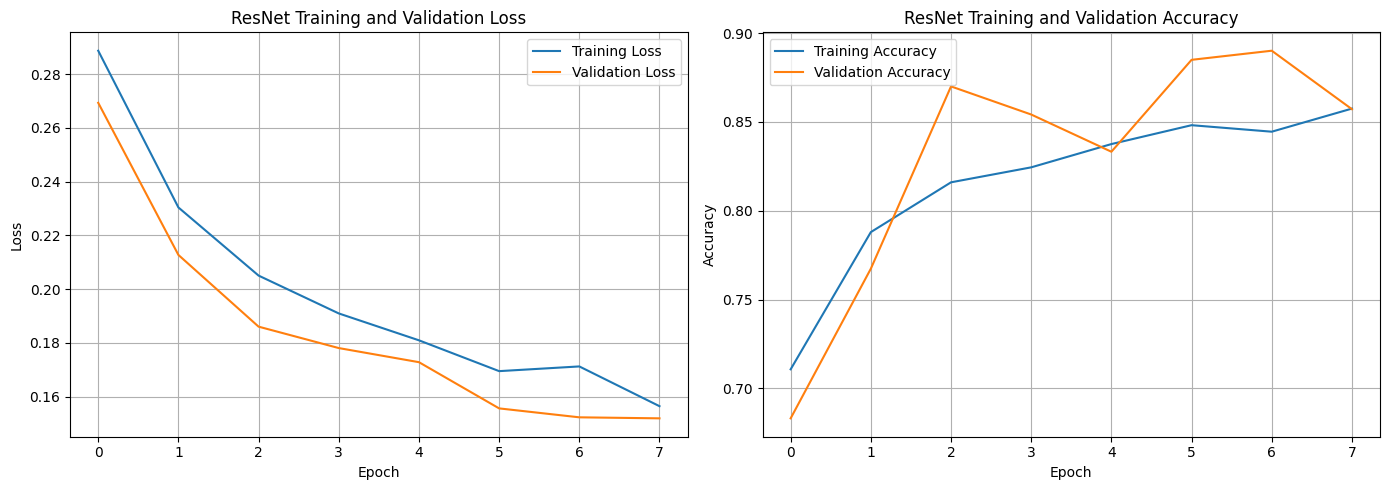

In [30]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet Training and Validation Loss")

plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [31]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= 0.5
        ).int().cpu().numpy().flatten()

        y_pred.extend(predictions)

        y_true.extend(
            labels.numpy().astype(int)
        )

print("DAY 10 RESNET CLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Healthy", "Diseased"],
        zero_division=0
    )
)

day10_accuracy = accuracy_score(
    y_true, y_pred
) * 100

print("Day 10 Test Accuracy:", day10_accuracy, "%")

DAY 10 RESNET CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy       0.68      0.95      0.79       633
    Diseased       0.98      0.84      0.90      1707

    accuracy                           0.87      2340
   macro avg       0.83      0.89      0.85      2340
weighted avg       0.90      0.87      0.87      2340

Day 10 Test Accuracy: 86.70940170940172 %


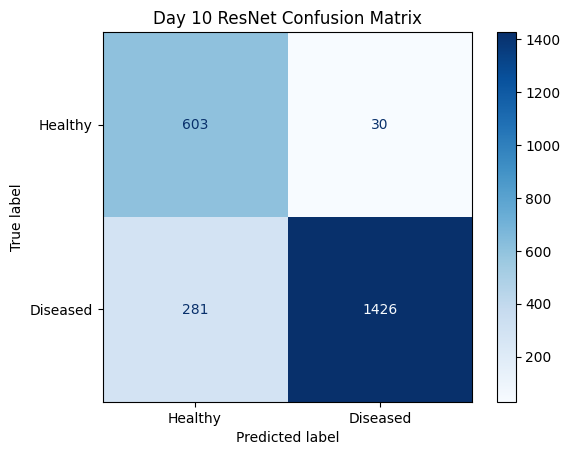

In [32]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Diseased"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Day 10 ResNet Confusion Matrix")
plt.show()

Individual leaf image prediction

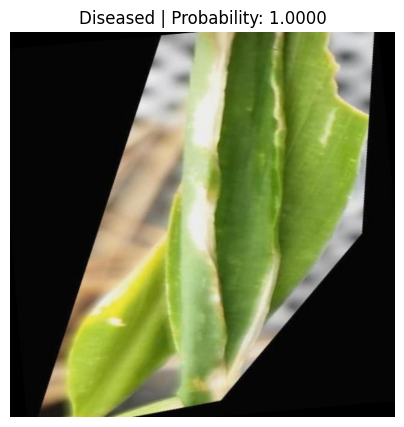

Prediction: Diseased
Disease Probability: 0.9999979734420776


In [33]:
def predict_resnet_leaf(image_path):

    model.eval()

    image = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = test_transform(image)

    input_tensor = input_tensor.unsqueeze(0).to(device)

    with torch.no_grad():

        output = model(input_tensor)

        probability = torch.sigmoid(output).item()

    prediction = (
        "Diseased" if probability >= 0.5
        else "Healthy"
    )

    plt.figure(figsize=(5, 5))

    plt.imshow(image)

    plt.title(
        f"{prediction} | Probability: {probability:.4f}"
    )

    plt.axis("off")
    plt.show()

    print("Prediction:", prediction)
    print("Disease Probability:", probability)


sample_image = test_df.iloc[0]["path"]

predict_resnet_leaf(sample_image)

FINAL MODEL SAVING

In [34]:
FINAL_MODEL_PATH = os.path.join(
    DAY10_DIR,
    "resnet_leaf_disease_final.pth"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "image_size": IMAGE_SIZE,
        "class_mapping": {
            "Healthy": 0,
            "Diseased": 1
        },
        "best_validation_loss": best_val_loss
    },
    FINAL_MODEL_PATH
)

print("Final ResNet model saved successfully!")
print(FINAL_MODEL_PATH)

Final ResNet model saved successfully!
/content/drive/MyDrive/Day10_ResNet/resnet_leaf_disease_final.pth


Comparision of Day 9 and 10

In [35]:
DAY9_ACCURACY_PATH = os.path.join(
    DAY9_EXPORT,
    "day9_accuracy.npy"
)

day9_accuracy = float(
    np.load(DAY9_ACCURACY_PATH)
)

comparison_df = pd.DataFrame({

    "Architecture": [
        "Day 9 - Shallow CNN",
        "Day 10 - ResNet"
    ],

    "Test Accuracy (%)": [
        day9_accuracy,
        day10_accuracy
    ]
})

display(comparison_df)

difference = day10_accuracy - day9_accuracy

print(
    "Accuracy Difference:",
    round(difference, 2),
    "percentage points"
)

if difference > 0:
    print("ResNet achieved higher test accuracy.")
elif difference < 0:
    print("Shallow CNN achieved higher test accuracy.")
else:
    print("Both models achieved equal test accuracy.")

,Architecture,Test Accuracy (%)
0,Day 9 - Shallow CNN,85.811966
1,Day 10 - ResNet,86.709402


Accuracy Difference: 0.9 percentage points
ResNet achieved higher test accuracy.
